# Uber Trips Data Cleaning, Quality Audit & Exploratory Analysis

This notebook builds directly on `cleaning.ipynb` and analyzes `trips_reviewed.csv` (50,000 ride-hailing trip records).

### What this notebook covers
1. **Setup & Data Loading** – Load `trips_reviewed.csv` and create a safe working copy.
2. **Basic Inspection & Cleaning** – Check shape, missing values, duplicates, column names, and date/time features.
3. **Sanity Checks & Status Breakdown** – Fix the case-sensitivity and missing variable issues from `cleaning.ipynb` (`Completed`, `Cancelled`, `No-Show`).
4. **Data Quality Flag Audit** – Inspect all 7 review flags included in `trips_reviewed.csv`.
5. **Exploratory Data Analysis (EDA) & Charts** – Analyze trip status, payment methods, city performance, hourly/daily demand, and fare vs. distance.
6. **Simple Statistical Analysis** – Measure the relationship between trip distance and fare amount.
7. **Exporting a Cleaned Dataset** – Filter valid completed trips and save a clean CSV for dashboards or modeling.

## 1. Setup & Data Loading

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set a clean visual style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load trips_reviewed.csv (place this notebook in the same folder as the CSV file)
file_path = "trips_reviewed.csv"

# Fallback path if running from a subfolder
if not os.path.exists(file_path):
    alt_path = os.path.join("user_uploaded_files", "ttl=63d", "user_uploaded", "trips_reviewed.csv")
    if os.path.exists(alt_path):
        file_path = alt_path

uber_df = pd.read_csv(file_path)

# Make a working copy so the original DataFrame stays untouched
uber_clean = uber_df.copy()

print("Loaded file:", file_path)
print("Dataset shape (rows, columns):", uber_clean.shape)
uber_clean.head()

Loaded file: user_uploaded_files/ttl=63d/user_uploaded/trips_reviewed.csv
Dataset shape (rows, columns): (50000, 24)


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time,duration_minutes,straight_line_km,pickup_to_named_city_center_km,flag_city_center_over_50km,flag_recorded_distance_less_than_straight_line_plus_10m,flag_zero_distance,flag_distance_under_0_1km,flag_distance_over_15km,flag_fare_over_40,flag_noncompleted_with_positive_fare_and_distance
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01 00:00:00,2023-01-01 00:08:54.600000000,8.91,2.9796,3918.25,True,False,False,False,False,False,False
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01 00:01:00,2023-01-01 00:26:17.400000000,25.29,4.8512,3164.07,True,False,False,False,False,False,False
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01 00:02:00,2023-01-01 00:18:22.800000000,16.38,4.0777,2821.65,True,False,False,False,False,False,False
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01 00:03:00,2023-01-01 00:22:49.800000000,19.83,1.1743,396.75,True,False,False,False,False,False,False
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01 00:04:00,2023-01-01 00:35:30.000000000,31.50,2.5452,962.48,True,False,False,False,False,False,False


## 2. Initial Inspection & Basic Cleaning

In [3]:
# Standardize column names (strip spaces, lowercase, replace spaces with underscores)
uber_clean.columns = (
    uber_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Columns in dataset:")
for i, col in enumerate(uber_clean.columns, start=1):
    print(f"  {i:2d}. {col} ({uber_clean[col].dtype})")

Columns in dataset:
   1. trip_id (int64)
   2. driver_id (int64)
   3. rider_id (int64)
   4. city (object)
   5. pickup_lat (float64)
   6. pickup_lng (float64)
   7. drop_lat (float64)
   8. drop_lng (float64)
   9. distance_km (float64)
  10. fare_amount (float64)
  11. status (object)
  12. payment_method (object)
  13. pickup_time (object)
  14. drop_time (object)
  15. duration_minutes (float64)
  16. straight_line_km (float64)
  17. pickup_to_named_city_center_km (float64)
  18. flag_city_center_over_50km (bool)
  19. flag_recorded_distance_less_than_straight_line_plus_10m (bool)
  20. flag_zero_distance (bool)
  21. flag_distance_under_0_1km (bool)
  22. flag_distance_over_15km (bool)
  23. flag_fare_over_40 (bool)
  24. flag_noncompleted_with_positive_fare_and_distance (bool)


In [4]:
# Check missing values and duplicate rows
missing_counts = uber_clean.isnull().sum()
total_missing = missing_counts.sum()
duplicate_count = uber_clean.duplicated().sum()

print("Total missing values across all columns:", total_missing)
print("Duplicate rows found:", duplicate_count)

# Drop duplicates if any exist
if duplicate_count > 0:
    uber_clean = uber_clean.drop_duplicates()
    print("Duplicates removed. New shape:", uber_clean.shape)
else:
    print("No duplicates to remove.")

Total missing values across all columns: 0
Duplicate rows found: 0
No duplicates to remove.


In [5]:
# Convert pickup_time and drop_time to datetime
uber_clean["pickup_time"] = pd.to_datetime(uber_clean["pickup_time"], errors="coerce")
uber_clean["drop_time"] = pd.to_datetime(uber_clean["drop_time"], errors="coerce")

# Create helpful date and time features (continuing from cleaning.ipynb)
uber_clean["trip_duration_min"] = (
    (uber_clean["drop_time"] - uber_clean["pickup_time"]).dt.total_seconds() / 60
)
uber_clean["pickup_hour"] = uber_clean["pickup_time"].dt.hour
uber_clean["pickup_day"] = uber_clean["pickup_time"].dt.day_name()
uber_clean["pickup_date"] = uber_clean["pickup_time"].dt.date
uber_clean["pickup_month"] = uber_clean["pickup_time"].dt.month_name()

print("Date range:", uber_clean["pickup_time"].min(), "to", uber_clean["pickup_time"].max())
print("Unique trips:  ", uber_clean["trip_id"].nunique())
print("Unique drivers:", uber_clean["driver_id"].nunique())
print("Unique riders: ", uber_clean["rider_id"].nunique())

Date range: 2023-01-01 00:00:00 to 2023-02-04 17:19:00
Unique trips:   50000
Unique drivers: 8963
Unique riders:  38352


In [6]:
# Summary statistics for key numeric columns
key_numeric_cols = [
    "distance_km",
    "fare_amount",
    "duration_minutes",
    "straight_line_km",
    "pickup_to_named_city_center_km"
]
uber_clean[key_numeric_cols].describe().round(2)

,distance_km,fare_amount,duration_minutes,straight_line_km,pickup_to_named_city_center_km
count,50000.00,50000.00,50000.00,50000.00,50000.00
mean,7.01,15.98,21.02,3.80,2009.86
std,2.95,6.27,8.84,1.45,1122.97
min,0.00,1.08,0.00,0.03,2.66
25%,4.98,11.51,14.94,2.77,1031.69
50%,6.98,15.43,20.94,3.91,1921.70
75%,9.00,19.91,27.00,4.92,2936.20
max,19.41,50.67,58.23,7.07,4322.62


## 3. Sanity Checks & Trip Status Breakdown

In the earlier `cleaning.ipynb`, filtering by lowercase `'completed'` and `'no_show'` returned 0 rows because the dataset uses Title Case (`'Completed'`, `'Cancelled'`, `'No-Show'`), and `cancelled_trips` was not yet defined. Below we fix both issues cleanly.

In [7]:
# Standardize text whitespace on status, city, and payment_method
uber_clean["status"] = uber_clean["status"].str.strip()
uber_clean["city"] = uber_clean["city"].str.strip()
uber_clean["payment_method"] = uber_clean["payment_method"].str.strip()

# Create basic sanity check flags (matching cleaning.ipynb logic)
uber_clean["zero_distance_flag"] = uber_clean["distance_km"] == 0
uber_clean["negative_distance_flag"] = uber_clean["distance_km"] < 0
uber_clean["invalid_duration_flag"] = uber_clean["trip_duration_min"] <= 0
uber_clean["negative_fare_flag"] = uber_clean["fare_amount"] < 0
uber_clean["high_fare_flag"] = uber_clean["fare_amount"] > 40

print("Basic Sanity Check Counts:")
print("  Zero distance trips:    ", int(uber_clean["zero_distance_flag"].sum()))
print("  Negative distance trips:", int(uber_clean["negative_distance_flag"].sum()))
print("  Invalid duration (<= 0):", int(uber_clean["invalid_duration_flag"].sum()))
print("  Negative fare trips:    ", int(uber_clean["negative_fare_flag"].sum()))
print("  High fare (> $40) trips:", int(uber_clean["high_fare_flag"].sum()))

Basic Sanity Check Counts:
  Zero distance trips:     3
  Negative distance trips: 0
  Invalid duration (<= 0): 3
  Negative fare trips:     0
  High fare (> $40) trips: 43


In [8]:
# Separate trips by status using exact values in the dataset
completed_trips = uber_clean[uber_clean["status"] == "Completed"]
cancelled_trips = uber_clean[uber_clean["status"] == "Cancelled"]
no_show_trips = uber_clean[uber_clean["status"] == "No-Show"]

total_trips = len(uber_clean)
print("Trip Status Breakdown:")
print(f"  Completed: {len(completed_trips):,} ({len(completed_trips) / total_trips * 100:.2f}%)")
print(f"  Cancelled: {len(cancelled_trips):,} ({len(cancelled_trips) / total_trips * 100:.2f}%)")
print(f"  No-Show:   {len(no_show_trips):,} ({len(no_show_trips) / total_trips * 100:.2f}%)")

Trip Status Breakdown:
  Completed: 42,540 (85.08%)
  Cancelled: 4,984 (9.97%)
  No-Show:   2,476 (4.95%)


## 4. Data Quality Flag Audit (`trips_reviewed.csv`)

`trips_reviewed.csv` already contains 7 pre-computed data quality flags (`flag_*`). Let's count how many trips trigger each flag and visualize them.

In [9]:
# Collect all pre-computed review flag columns
flag_columns = []
for col in uber_clean.columns:
    if col.startswith("flag_"):
        flag_columns.append(col)

# Build a clean summary table of flag counts and percentages
flag_rows = []
for col in flag_columns:
    count = int(uber_clean[col].sum())
    pct = round(count / len(uber_clean) * 100, 2)
    flag_rows.append({
        "flag_name": col,
        "flagged_trips": count,
        "percent_of_total": pct
    })

flag_summary = pd.DataFrame(flag_rows).sort_values("flagged_trips", ascending=False)
flag_summary = flag_summary.reset_index(drop=True)
flag_summary

,flag_name,flagged_trips,percent_of_total
0,flag_city_center_over_50km,49971,99.94
1,flag_recorded_distance_less_than_straight_line...,8472,16.94
2,flag_noncompleted_with_positive_fare_and_distance,7459,14.92
3,flag_distance_over_15km,216,0.43
4,flag_distance_under_0_1km,72,0.14
5,flag_fare_over_40,43,0.09
6,flag_zero_distance,3,0.01


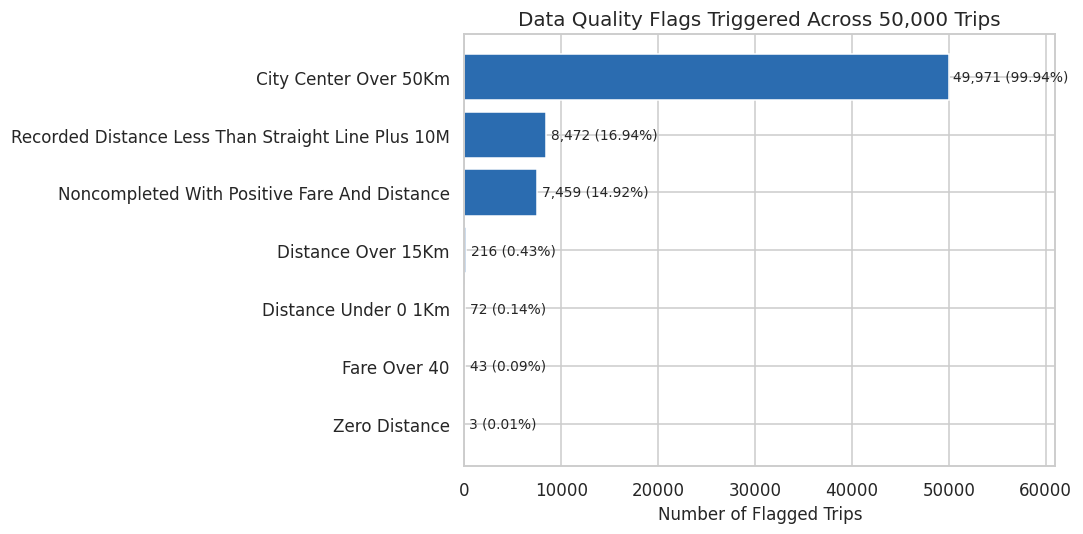

In [10]:
# Plot the data quality flag counts
fig, ax = plt.subplots(figsize=(10, 5))

short_labels = [
    name.replace("flag_", "").replace("_", " ").title()
    for name in flag_summary["flag_name"]
]

bars = ax.barh(short_labels[::-1], flag_summary["flagged_trips"][::-1], color="#2b6cb0")
ax.set_title("Data Quality Flags Triggered Across 50,000 Trips")
ax.set_xlabel("Number of Flagged Trips")

# Add count and percentage labels next to each bar
for bar, pct in zip(bars, flag_summary["percent_of_total"][::-1]):
    width = bar.get_width()
    ax.text(width + 500, bar.get_y() + bar.get_height() / 2,
            f"{int(width):,} ({pct:.2f}%)", va="center", fontsize=9)

ax.set_xlim(0, max(flag_summary["flagged_trips"]) * 1.22)
plt.tight_layout()
plt.show()

**Key Audit Observation:**
- `flag_city_center_over_50km` is `True` for **99.94%** (49,971) of rows because the synthetic pickup coordinates span a wide geographic range rather than clustering near each named city's downtown center.
- The most actionable **operational/billing anomalies** are:
  - `flag_recorded_distance_less_than_straight_line_plus_10m` (8,472 trips / 16.94%)
  - `flag_noncompleted_with_positive_fare_and_distance` (7,459 trips / 14.92% — nearly all Cancelled and No-Show trips still have recorded fares and distances)

## 5. Exploratory Data Analysis (EDA) & Visualizations

In [11]:
# Cross-tabulation of Trip Status vs. Payment Method
status_payment_ct = pd.crosstab(
    uber_clean["status"],
    uber_clean["payment_method"],
    margins=True
)
status_payment_ct

payment_method,Card,Cash,UPI,Wallet,All
status,,,,,
Cancelled,1196,1230,1307,1251,4984
Completed,10676,10568,10652,10644,42540
No-Show,661,615,590,610,2476
All,12533,12413,12549,12505,50000


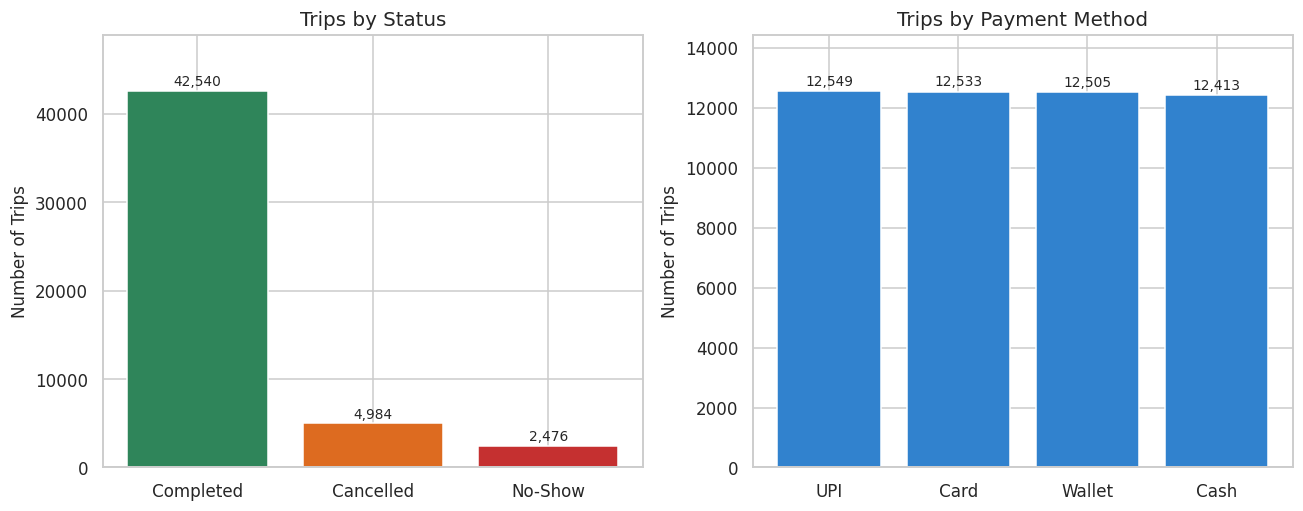

In [12]:
# Visualize Trip Status and Payment Method distributions side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

status_counts = uber_clean["status"].value_counts()
axes[0].bar(status_counts.index, status_counts.values, color=["#2f855a", "#dd6b20", "#c53030"])
axes[0].set_title("Trips by Status")
axes[0].set_ylabel("Number of Trips")
for idx, val in enumerate(status_counts.values):
    axes[0].text(idx, val + 600, f"{val:,}", ha="center", fontsize=9)
axes[0].set_ylim(0, status_counts.max() * 1.15)

payment_counts = uber_clean["payment_method"].value_counts()
axes[1].bar(payment_counts.index, payment_counts.values, color="#3182ce")
axes[1].set_title("Trips by Payment Method")
axes[1].set_ylabel("Number of Trips")
for idx, val in enumerate(payment_counts.values):
    axes[1].text(idx, val + 200, f"{val:,}", ha="center", fontsize=9)
axes[1].set_ylim(0, payment_counts.max() * 1.15)

plt.tight_layout()
plt.show()

In [13]:
# City-level performance summary on Completed trips
city_summary = completed_trips.groupby("city").agg(
    completed_trips=("trip_id", "count"),
    total_revenue=("fare_amount", "sum"),
    avg_fare=("fare_amount", "mean"),
    avg_distance_km=("distance_km", "mean"),
    avg_duration_min=("duration_minutes", "mean")
).reset_index()

city_summary = city_summary.sort_values("total_revenue", ascending=False).reset_index(drop=True)
city_summary.round(2)

,city,completed_trips,total_revenue,avg_fare,avg_distance_km,avg_duration_min
0,Boston,7182,115028.20,16.02,7.01,21.02
1,San Francisco,7159,114660.65,16.02,7.04,21.11
2,Seattle,7039,113343.20,16.10,7.08,21.25
3,New York,7036,113175.20,16.09,7.03,21.08
4,Chicago,7091,112791.09,15.91,6.96,20.87
5,Los Angeles,7033,110686.54,15.74,6.94,20.82


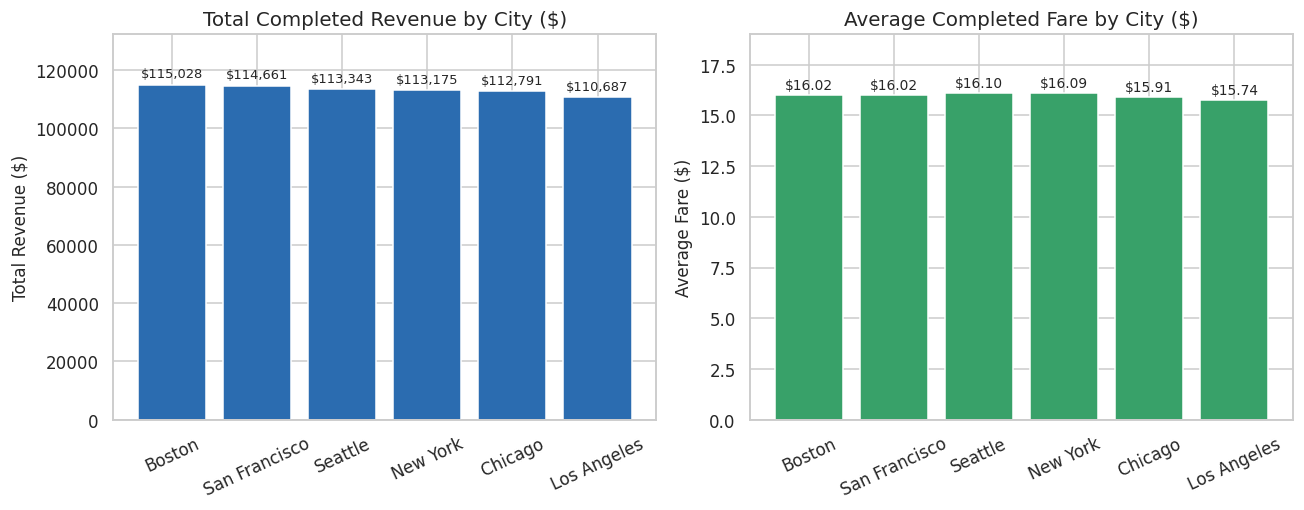

In [14]:
# Visualize Total Revenue and Average Fare by City (Completed Trips)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].bar(city_summary["city"], city_summary["total_revenue"], color="#2b6cb0")
axes[0].set_title("Total Completed Revenue by City ($)")
axes[0].set_ylabel("Total Revenue ($)")
axes[0].tick_params(axis="x", rotation=25)
for idx, val in enumerate(city_summary["total_revenue"]):
    axes[0].text(idx, val + 2500, f"${val:,.0f}", ha="center", fontsize=8.5)
axes[0].set_ylim(0, city_summary["total_revenue"].max() * 1.15)

axes[1].bar(city_summary["city"], city_summary["avg_fare"], color="#38a169")
axes[1].set_title("Average Completed Fare by City ($)")
axes[1].set_ylabel("Average Fare ($)")
axes[1].tick_params(axis="x", rotation=25)
for idx, val in enumerate(city_summary["avg_fare"]):
    axes[1].text(idx, val + 0.3, f"${val:.2f}", ha="center", fontsize=9)
axes[1].set_ylim(0, city_summary["avg_fare"].max() * 1.18)

plt.tight_layout()
plt.show()

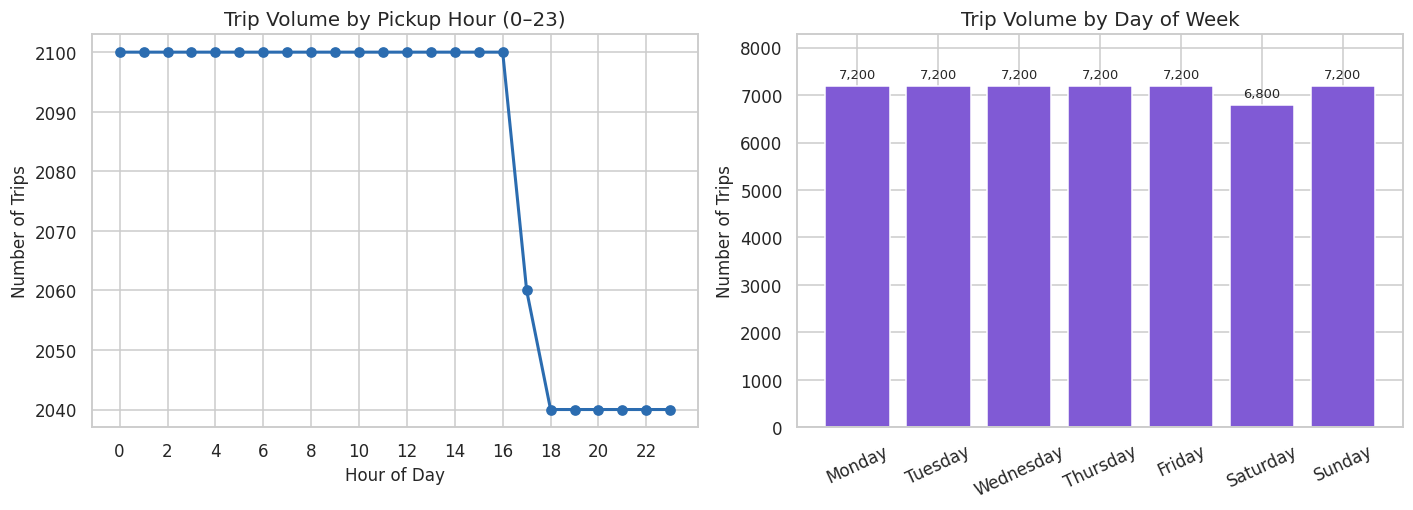

In [15]:
# Hourly and Day-of-Week trip demand patterns
hourly_counts = uber_clean.groupby("pickup_hour")["trip_id"].count()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_counts = uber_clean["pickup_day"].value_counts().reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(hourly_counts.index, hourly_counts.values, marker="o", color="#2b6cb0", linewidth=2)
axes[0].set_title("Trip Volume by Pickup Hour (0–23)")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Number of Trips")
axes[0].set_xticks(range(0, 24, 2))

axes[1].bar(daily_counts.index, daily_counts.values, color="#805ad5")
axes[1].set_title("Trip Volume by Day of Week")
axes[1].set_ylabel("Number of Trips")
axes[1].tick_params(axis="x", rotation=25)
for idx, val in enumerate(daily_counts.values):
    axes[1].text(idx, val + 150, f"{val:,}", ha="center", fontsize=8.5)
axes[1].set_ylim(0, daily_counts.max() * 1.15)

plt.tight_layout()
plt.show()

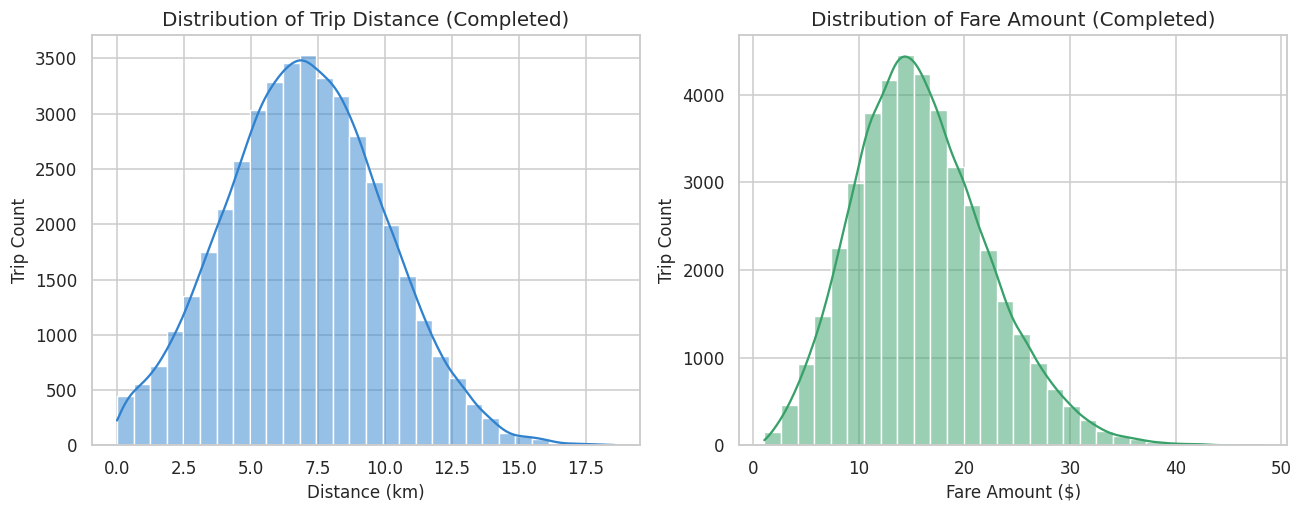

In [16]:
# Distributions of Distance and Fare Amount (Completed Trips)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

sns.histplot(completed_trips["distance_km"], bins=30, kde=True, color="#3182ce", ax=axes[0])
axes[0].set_title("Distribution of Trip Distance (Completed)")
axes[0].set_xlabel("Distance (km)")
axes[0].set_ylabel("Trip Count")

sns.histplot(completed_trips["fare_amount"], bins=30, kde=True, color="#38a169", ax=axes[1])
axes[1].set_title("Distribution of Fare Amount (Completed)")
axes[1].set_xlabel("Fare Amount ($)")
axes[1].set_ylabel("Trip Count")

plt.tight_layout()
plt.show()

In [17]:
# Top 10 Drivers by Completed Trip Count and Revenue
top_drivers = completed_trips.groupby("driver_id").agg(
    completed_trips=("trip_id", "count"),
    total_revenue=("fare_amount", "sum"),
    avg_fare=("fare_amount", "mean"),
    total_distance_km=("distance_km", "sum")
).reset_index()

top_drivers = top_drivers.sort_values("total_revenue", ascending=False).head(10).reset_index(drop=True)
top_drivers.round(2)

,driver_id,completed_trips,total_revenue,avg_fare,total_distance_km
0,6599,15,262.25,17.48,111.56
1,1027,14,249.96,17.85,103.18
2,8008,14,223.18,15.94,102.20
3,4138,11,221.80,20.16,95.47
4,4343,12,221.14,18.43,87.24
5,4718,11,219.53,19.96,95.47
6,3261,12,216.64,18.05,87.66
7,3925,13,209.74,16.13,96.78
8,3256,11,209.00,19.00,90.14
9,9199,10,207.35,20.74,94.42


## 6. Simple Statistical Analysis: Distance vs. Fare

Linear Regression: Fare Amount vs. Distance (Completed Trips)
  Estimated Base Fare (Intercept): $2.98
  Estimated Rate per km (Slope):   $1.85 / km
  Correlation (r):                 0.8708
  R-squared (R^2):                 0.7582
  P-value:                         0.0000e+00


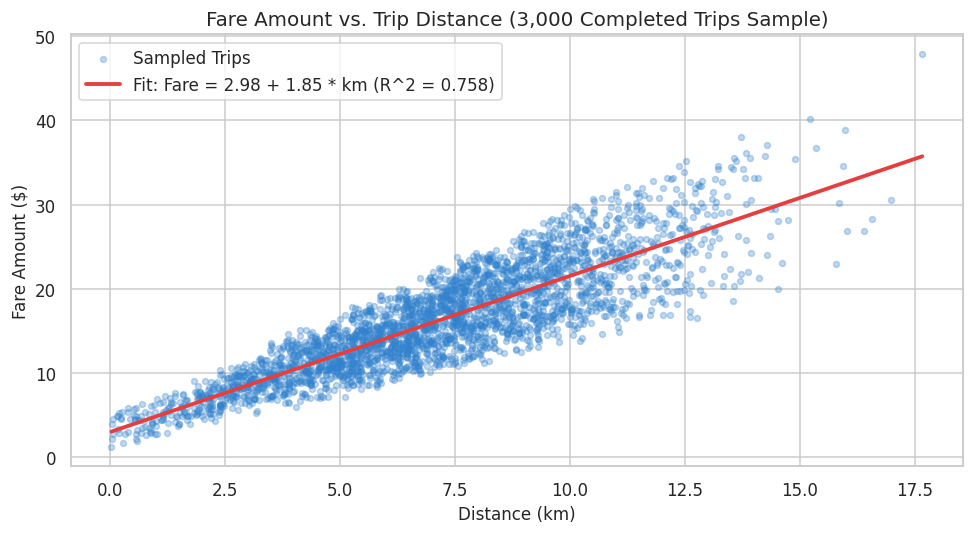

In [18]:
# Run a linear regression between distance_km and fare_amount on Completed trips
reg = stats.linregress(completed_trips["distance_km"], completed_trips["fare_amount"])

print("Linear Regression: Fare Amount vs. Distance (Completed Trips)")
print(f"  Estimated Base Fare (Intercept): ${reg.intercept:.2f}")
print(f"  Estimated Rate per km (Slope):   ${reg.slope:.2f} / km")
print(f"  Correlation (r):                 {reg.rvalue:.4f}")
print(f"  R-squared (R^2):                 {reg.rvalue ** 2:.4f}")
print(f"  P-value:                         {reg.pvalue:.4e}")

# Plot a 3,000-row sample scatter plot with the fitted regression line
sample_df = completed_trips.sample(n=3000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample_df["distance_km"], sample_df["fare_amount"], alpha=0.3, s=15, color="#3182ce", label="Sampled Trips")

x_vals = np.linspace(sample_df["distance_km"].min(), sample_df["distance_km"].max(), 100)
y_vals = reg.intercept + reg.slope * x_vals
ax.plot(x_vals, y_vals, color="#e53e3e", linewidth=2.5,
        label=f"Fit: Fare = {reg.intercept:.2f} + {reg.slope:.2f} * km (R^2 = {reg.rvalue**2:.3f})")

ax.set_title("Fare Amount vs. Trip Distance (3,000 Completed Trips Sample)")
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Fare Amount ($)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Building & Exporting a Clean Analytical Dataset

Because `flag_city_center_over_50km` affects 99.94% of rows due to synthetic coordinate generation, dropping all rows with *any* flag would leave only 21 rows. Instead, a practical cleaning rule for business/fare analysis is to keep **Completed trips** that pass all operational and distance-consistency checks:
- `status == "Completed"`
- `distance_km > 0`
- `trip_duration_min > 0`
- `fare_amount >= 0`
- `flag_recorded_distance_less_than_straight_line_plus_10m == False`

In [19]:
# Build the clean operational dataset
clean_completed_df = uber_clean[
    (uber_clean["status"] == "Completed") &
    (uber_clean["distance_km"] > 0) &
    (uber_clean["trip_duration_min"] > 0) &
    (uber_clean["fare_amount"] >= 0) &
    (uber_clean["flag_recorded_distance_less_than_straight_line_plus_10m"] == False)
].copy()

# Add two simple derived metrics
clean_completed_df["fare_per_km"] = (clean_completed_df["fare_amount"] / clean_completed_df["distance_km"]).round(2)
clean_completed_df["avg_speed_kmh"] = (clean_completed_df["distance_km"] / (clean_completed_df["trip_duration_min"] / 60)).round(2)

print("Original rows:            ", f"{len(uber_clean):,}")
print("Clean completed rows kept:", f"{len(clean_completed_df):,} ({len(clean_completed_df) / len(uber_clean) * 100:.2f}%)")
print("Rows excluded:            ", f"{len(uber_clean) - len(clean_completed_df):,}")

# Export cleaned dataset (uncomment the line below to save locally)
# clean_completed_df.to_csv("trips_cleaned_completed.csv", index=False)

clean_completed_df[["trip_id", "city", "distance_km", "fare_amount", "trip_duration_min", "fare_per_km", "avg_speed_kmh"]].head()

Original rows:             50,000
Clean completed rows kept: 35,299 (70.60%)
Rows excluded:             14,701


,trip_id,city,distance_km,fare_amount,trip_duration_min,fare_per_km,avg_speed_kmh
0,1,San Francisco,2.97,10.71,8.91,3.61,20.0
1,2,Boston,8.43,22.41,25.29,2.66,20.0
2,3,San Francisco,5.46,12.91,16.38,2.36,20.0
3,4,New York,6.61,15.70,19.83,2.38,20.0
4,5,Seattle,10.50,19.15,31.50,1.82,20.0
